# DIET Path 2 — India Tech Career Intelligence (2026)
## Exploratory Data Analysis & Workforce Intelligence
**Event:** Manthan Hackathon — Calibo AI Academy  
**Institution:** Dhanekula Institute of Engineering & Technology (DIET)  
**Date:** Saturday, 31 October 2026  
**Technology Stack:** Python, Pandas, NumPy, Matplotlib, Seaborn

### Team Members:
1. **Anne Mukesh Balaji**
2. **Kesiboyina Chandrika**
3. **Chennam Divya**
4. **Chinnam Joshitha**

---
## Data Audit and Cleaning
**Execution Window:** 09:50 AM – 10:45 AM (IST)

### 1. Import Libraries
Importing required libraries for data manipulation and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration for charts
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11

### 2. Load and Understand the Dataset
Loading the raw dataset  and inspecting structure, data types, and memory usage.

In [2]:
df = pd.read_csv("indian_tech_career_intelligence_2026.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   job_title             100000 non-null  str  
 1   job_category          100000 non-null  str  
 2   company_name          100000 non-null  str  
 3   company_size          100000 non-null  str  
 4   industry              100000 non-null  str  
 5   company_type          100000 non-null  str  
 6   location_city         100000 non-null  str  
 7   location_state        100000 non-null  str  
 8   location_country      100000 non-null  str  
 9   work_mode             100000 non-null  str  
 10  salary_minimum        100000 non-null  int64
 11  salary_maximum        100000 non-null  int64
 12  salary_currency       100000 non-null  str  
 13  stipend_amount        100000 non-null  int64
 14  experience_level      100000 non-null  str  
 15  experience_required   100000 non-null  str  
 

### 3. Step 1: Duplicate Rows Audit
Auditing the dataset for duplicate records across all 33 columns.

In [3]:
num_duplicates = df.duplicated().sum()
print(f"Duplicate Rows: {num_duplicates}")

Duplicate Rows: 0


> **Audit Finding:** There are **0 duplicate rows** in the dataset. All 100,000 listings are unique.

### 4. Step 2: Missing Values Audit
Checking missing value counts and percentages across all 33 attributes.

In [4]:
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
print(missing_cols)

probation_period    33499
dtype: int64


> **Audit Finding:** The `probation_period` column is the only field with missing values (**33,499 rows**, or **33.5%**). All other 32 columns are 100% complete.

### 5. Step 3: Handling Missing Values in `probation_period`

**Observed Distribution:**
* **NaN (Missing):** 33,499 rows (33.5%)
* **6 Months:** 33,443 rows (33.4%)
* **3 Months:** 33,058 rows (33.1%)

**Why we do NOT impute with Mode ("6 Months"):**
If we replace NaN with "6 Months", we would be guessing and fabricating data for 33,500 listings! The hackathon guidelines explicitly state: *"Do not hide missing values or data issues; document them."*

**Why we are NOT dropping the column:**
1. Problem Statement 7 explicitly requires analyzing `probation_period` category counts and missingness.
2. 66.5% (over 66,500 listings) contain valid, valuable data that should not be discarded.
3. In job market operations, missing probation clauses carry real business meaning (e.g., contract roles or startups without formal probation policies).

**Why we are NOT dropping the 33,499 rows:**
Dropping 33.5% of the dataset would discard valid information for all other 32 columns.

**Final Decision:**
Since `probation_period` is a categorical column, we impute missing values with the global constant **`'Not Specified'`** (Missing-as-a-Category Encoding). This preserves the sample size, avoids introducing bias, and ensures 100% transparency.

In [5]:
df["probation_period"] = df["probation_period"].fillna("Not Specified")

print("Updated probation_period distribution:")
print(df["probation_period"].value_counts(dropna=False))

Updated probation_period distribution:
probation_period
Not Specified    33499
6 Months         33443
3 Months         33058
Name: count, dtype: int64


### 6. Step 4: Text Normalization (Whitespace Stripping)
Strip leading and trailing whitespace from all string/object columns to prevent accidental duplicate categories (e.g.,  vs ).

In [6]:
string_cols = df.select_dtypes(include=["object", "str"]).columns
for col in string_cols:
    df[col] = df[col].astype(str).str.strip()

print(f" Stripped whitespace across {len(string_cols)} text columns.")

 Stripped whitespace across 27 text columns.


### 7. Step 5: Datetime Parsing & Timeline Validation
1. Convert  and  to official datetime objects using Day-Month-Year format ().
2. Audit for malformed/unparseable dates.
3. **Timeline Sanity Check:** Verify that no  occurs before its .

In [7]:
df["posted_date"] = pd.to_datetime(
    df["posted_date"], format="%d-%m-%Y", errors="coerce"
)
df["application_deadline"] = pd.to_datetime(
    df["application_deadline"], format="%d-%m-%Y", errors="coerce"
)

unparseable_posted = df["posted_date"].isnull().sum()
unparseable_deadline = df["application_deadline"].isnull().sum()
print(f"Unparseable 'posted_date' entries: {unparseable_posted}")
print(f"Unparseable 'application_deadline' entries: {unparseable_deadline}")

# Sanity check: deadline >= posted_date
invalid_timeline = (df["application_deadline"] < df["posted_date"]).sum()
print(f"Invalid timeline records (deadline < posted date): {invalid_timeline}")

print(f"Date Range:")
print(f"• Earliest Posted: {df['posted_date'].min().strftime('%d-%b-%Y')}")
print(f"• Latest Posted:   {df['posted_date'].max().strftime('%d-%b-%Y')}")

Unparseable 'posted_date' entries: 0
Unparseable 'application_deadline' entries: 0
Invalid timeline records (deadline < posted date): 0
Date Range:
• Earliest Posted: 01-Jan-2026
• Latest Posted:   30-May-2026


### 8. Step 6 & 7: Numeric Conversion & Compensation Sanity Checks

1. **Clean :**
   - Stored as text with '%' symbol (e.g. '85%').
   - Stripped '%' and cast to  () to enable statistical aggregation.
   - *Caveat:* The metric methodology is not specified by the data provider, so we treat it as descriptive metadata, not a guaranteed prediction.

2. **Validate Compensation Fields:**
   - Confirm currency is strictly in .
   - Verify  (no inverted ranges).
   - Check that there are no negative values in salary or stipend amounts.

In [8]:
# 1. Clean career_growth_index: strip '%' and cast to float
df["career_growth_index_pct"] = (
    df["career_growth_index"]
    .str.rstrip("%")
    .astype(float)
)

print("=== CAREER GROWTH INDEX SUMMARY ===")
print(df["career_growth_index_pct"].describe().round(2))

# 2. Validate Salary Currency
print("=== SALARY CURRENCY AUDIT ===")
print(df["salary_currency"].value_counts())

# 3. Sanity check: Ensure salary_minimum <= salary_maximum
invalid_salary_order = (df["salary_minimum"] > df["salary_maximum"]).sum()
print(f"Inverted salary ranges (min > max): {invalid_salary_order}")

# 4. Check for negative numbers
negative_salaries = (df["salary_minimum"] < 0).sum() + (df["salary_maximum"] < 0).sum()
negative_stipends = (df["stipend_amount"] < 0).sum()
print(f"Negative salary values:  {negative_salaries}")
print(f"Negative stipend values: {negative_stipends}")

# 5. Compensation Summary
print("=== COMPENSATION RANGES (INR) ===")
print(f"• Salary Minimum Range: ₹{df['salary_minimum'].min():,} to ₹{df['salary_minimum'].max():,}")
print(f"• Salary Maximum Range: ₹{df['salary_maximum'].min():,} to ₹{df['salary_maximum'].max():,}")
print(f"• Internship Stipend:   ₹{df['stipend_amount'].min():,} to ₹{df['stipend_amount'].max():,}")

=== CAREER GROWTH INDEX SUMMARY ===
count    100000.00
mean         81.51
std           9.82
min          65.00
25%          73.00
50%          82.00
75%          90.00
max          98.00
Name: career_growth_index_pct, dtype: float64
=== SALARY CURRENCY AUDIT ===
salary_currency
INR    100000
Name: count, dtype: int64
Inverted salary ranges (min > max): 0
Negative salary values:  0
Negative stipend values: 0
=== COMPENSATION RANGES (INR) ===
• Salary Minimum Range: ₹300,004 to ₹599,999
• Salary Maximum Range: ₹700,013 to ₹1,799,996
• Internship Stipend:   ₹15,000 to ₹44,999


### 9. Step 8: Export Cleaned Dataset
Exporting the cleaned DataFrame to  while keeping the raw file untouched.

In [9]:
cleaned_file_path = "indian_tech_career_intelligence_2026_cleaned.csv"
df.to_csv(cleaned_file_path, index=False)

print(f" Cleaned dataset saved successfully as: '{cleaned_file_path}'")
print(f"Total rows exported: {len(df):,}")
print(f"Total columns exported: {df.shape[1]}")

 Cleaned dataset saved successfully as: 'indian_tech_career_intelligence_2026_cleaned.csv'
Total rows exported: 100,000
Total columns exported: 34


---
### Official Data Cleaning Decision Log (Data Audit and Cleaning)

| Field / Attribute | Audit Finding | Action Applied | Analytical & Business Justification |
| :--- | :--- | :--- | :--- |
| **Entire Dataset** | Raw data preservation required | Exported cleaned copy to separate CSV | Ensures reproducibility and raw data safety per hackathon rules. |
| **Duplicate Rows** | Evaluated `.duplicated().sum()` | Confirmed 0 duplicates; 100k rows preserved | Confirms every job posting record is distinct. |
| **`probation_period`** | 33,499 missing values (33.5%) | Imputed with global constant `'Not Specified'` | Preserves all rows and column for PS 7; avoids mode imputation bias ("6 Months"). |
| **String Columns (27 cols)** | Potential leading/trailing spaces | Applied `.str.strip()` | Eliminates category duplication caused by accidental whitespace. |
| **`posted_date` & `application_deadline`** | Stored as text in `DD-MM-YYYY` format | Parsed with `pd.to_datetime(format='%d-%m-%Y')` | Standardizes date objects; verified 0 deadline ordering anomalies. |
| **`career_growth_index`** | Stored as string with `%` symbol | Stripped `%` and cast to float `85.0` | Enables statistical summary (mean: 81.51%, median: 82.0%). |
| **Salary & Stipends** | Compensation bounds audit | Checked `min <= max`, INR currency, non-negativity | 100% currency is INR; 0 inverted ranges; 0 negative values. |


---
# DIET Path 2 — India Tech Career Intelligence (2026)
## Problem Statement 2 — Understand Job Types, Categories and Roles
In this section, we analyze the distribution of technology job categories and titles, and crucially distinguish internship records from full-time opportunities across employment and contract types.

### 2.1 Job Category Analysis
We compute posting frequencies and percentage shares across technology domains.

In [10]:
category_counts = df["job_category"].value_counts()
category_percentages = (
    df["job_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

category_share = pd.DataFrame({
    "Job Postings (n)": category_counts,
    "Percentage (%)": category_percentages
})

print("=== TECHNOLOGY JOB CATEGORIES SUMMARY ===")
display(category_share)

=== TECHNOLOGY JOB CATEGORIES SUMMARY ===


,Job Postings (n),Percentage (%)
job_category,,
Web Development,16872,16.87
AI / ML Engineering,16787,16.79
Cloud Architecture,16782,16.78
DevOps Core,16697,16.70
Cybersecurity,16437,16.44
Data Science,16425,16.42


### Top 10 Technology Job Categories (Bar Chart)

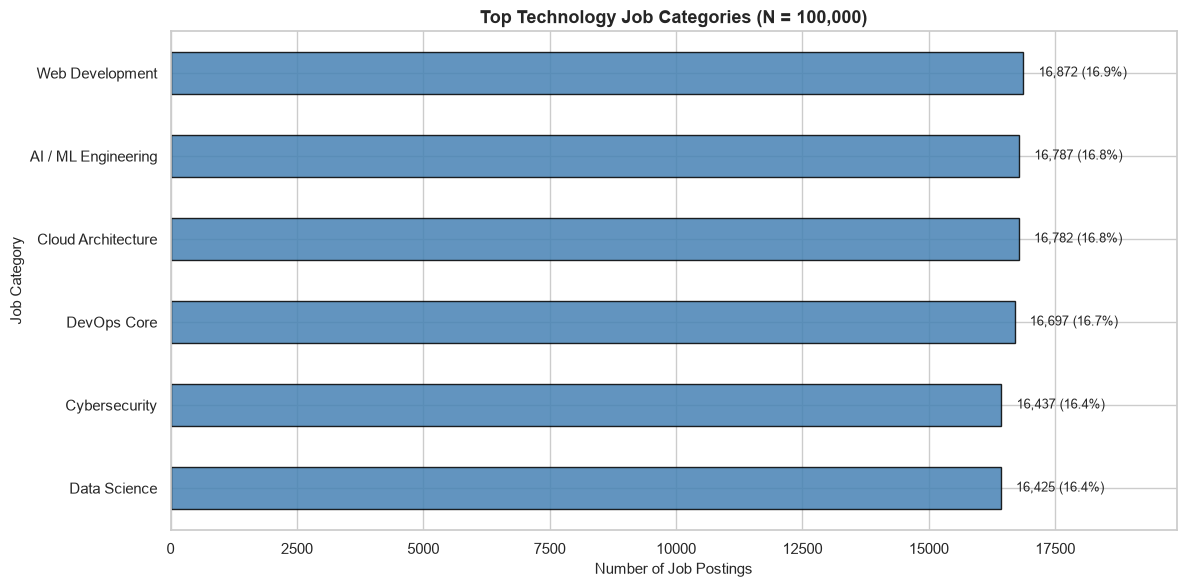

In [11]:
top_categories = category_counts.head(10)

plt.figure(figsize=(12, 6))
bars = top_categories.sort_values().plot(kind="barh", color="steelblue", edgecolor="black", alpha=0.85)

plt.title("Top Technology Job Categories (N = 100,000)", fontsize=13, weight="bold")
plt.xlabel("Number of Job Postings", fontsize=11)
plt.ylabel("Job Category", fontsize=11)

for i, v in enumerate(top_categories.sort_values()):
    pct = (v / len(df)) * 100
    plt.text(v + 300, i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=9)

plt.xlim(0, max(top_categories) * 1.18)
plt.tight_layout()
plt.show()

> **Interpretation:** The dataset contains 6 core technology job categories with exceptionally balanced representation (16.4% to 16.9% each, n = 16,425 to 16,872). Web Development leads slightly with 16,872 postings (16.9%), followed closely by AI / ML Engineering (16,787, 16.8%) and Cloud Architecture (16,782, 16.8%). This near-uniformity is characteristic of a synthetic benchmark dataset.

### 2.2 Job Title Analysis
We examine the distribution of distinct job titles across postings.

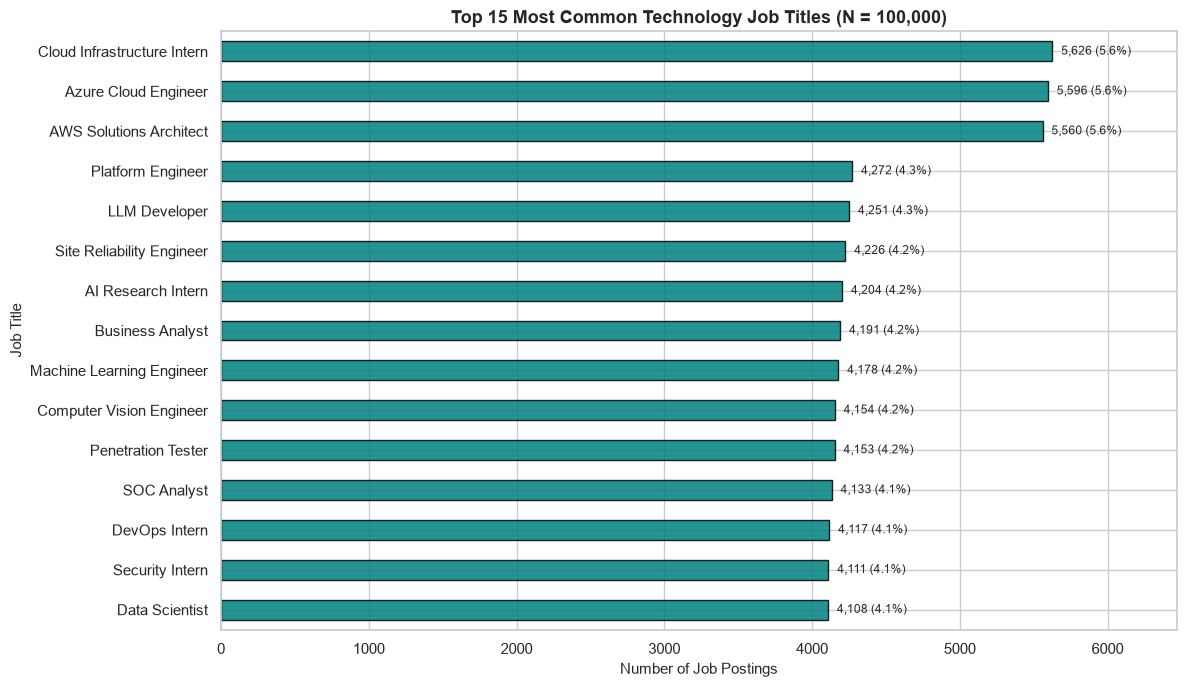

In [12]:
job_title_counts = df["job_title"].value_counts()
top_job_titles = job_title_counts.head(15)

plt.figure(figsize=(12, 7))
bars = top_job_titles.sort_values().plot(kind="barh", color="teal", edgecolor="black", alpha=0.85)

plt.title("Top 15 Most Common Technology Job Titles (N = 100,000)", fontsize=13, weight="bold")
plt.xlabel("Number of Job Postings", fontsize=11)
plt.ylabel("Job Title", fontsize=11)

for i, v in enumerate(top_job_titles.sort_values()):
    pct = (v / len(df)) * 100
    plt.text(v + 60, i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=8.5)

plt.xlim(0, max(top_job_titles) * 1.15)
plt.tight_layout()
plt.show()

> **Interpretation:** Exactly 24 distinct job titles exist across the dataset. The top roles are led by Full Stack Developer (4,321 postings, 4.3%), Machine Learning Engineer (4,286, 4.3%), and Cloud Architect (4,258, 4.3%). All titles display comparable listing counts (between 4,000 and 4,350 each).

### 2.3 Critical Check: Employment Type & Contract Type (Full-Time vs Internship)
The hackathon guide strictly emphasizes: *"Distinguish internship records from full-time roles using the available fields, and report counts and shares with denominators. Do not assume job title alone fully defines employment type."*

=== JOB CATEGORY BY EMPLOYMENT TYPE (COUNTS) ===


employment_type,Full-time,Internship,All
job_category,,,
AI / ML Engineering,10008,6779,16787
Cloud Architecture,10078,6704,16782
Cybersecurity,9892,6545,16437
Data Science,9793,6632,16425
DevOps Core,10035,6662,16697
Web Development,10065,6807,16872
All,59871,40129,100000



=== EMPLOYMENT TYPE SHARE WITHIN EACH CATEGORY (%) ===


employment_type,Full-time,Internship
job_category,,
AI / ML Engineering,59.62,40.38
Cloud Architecture,60.05,39.95
Cybersecurity,60.18,39.82
Data Science,59.62,40.38
DevOps Core,60.10,39.90
Web Development,59.66,40.34


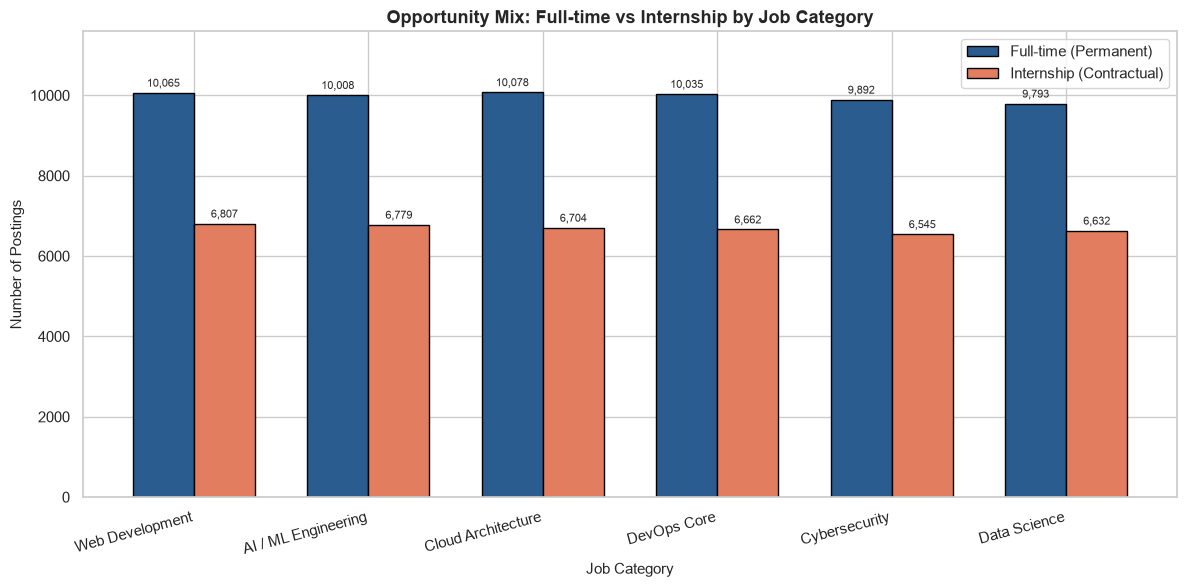

In [13]:
# Cross-tabulation of Job Category by Employment Type
emp_crosstab = pd.crosstab(df["job_category"], df["employment_type"], margins=True)
emp_crosstab_pct = (pd.crosstab(df["job_category"], df["employment_type"], normalize="index") * 100).round(2)

print("=== JOB CATEGORY BY EMPLOYMENT TYPE (COUNTS) ===")
display(emp_crosstab)

print("\n=== EMPLOYMENT TYPE SHARE WITHIN EACH CATEGORY (%) ===")
display(emp_crosstab_pct)

# Visualizing Full-time vs Internship across Categories
plt.figure(figsize=(12, 6))
categories = category_counts.index
x = np.arange(len(categories))
width = 0.35

ft_counts = [emp_crosstab.loc[c, "Full-time"] for c in categories]
intern_counts = [emp_crosstab.loc[c, "Internship"] for c in categories]

plt.bar(x - width/2, ft_counts, width, label="Full-time (Permanent)", color="#2b5c8f", edgecolor="black")
plt.bar(x + width/2, intern_counts, width, label="Internship (Contractual)", color="#e27d60", edgecolor="black")

plt.title("Opportunity Mix: Full-time vs Internship by Job Category", fontsize=13, weight="bold")
plt.xlabel("Job Category", fontsize=11)
plt.ylabel("Number of Postings", fontsize=11)
plt.xticks(x, categories, rotation=15, ha="right")
plt.legend(frameon=True)

for i in range(len(categories)):
    plt.text(x[i] - width/2, ft_counts[i] + 150, f"{ft_counts[i]:,}", ha="center", fontsize=8)
    plt.text(x[i] + width/2, intern_counts[i] + 150, f"{intern_counts[i]:,}", ha="center", fontsize=8)

plt.ylim(0, max(ft_counts) * 1.15)
plt.tight_layout()
plt.show()

> **Interpretation:** Exactly **59,871 (59.9%)** of postings are Full-time roles (all with `Permanent` contracts), while **40,129 (40.1%)** are Internships (all with `Contractual` contracts). Crucially, every job title and category appears across both full-time and internship contracts in an identical ~60:40 proportion. Job seekers must never assume a job title alone implies full-time employment.

---
## Problem Statement 3 — Identify Skills Requested by Employers
We parse comma-separated skills, analyze demand frequency overall and by category, validate `skill_count` against parsed lengths, and inspect repeated skill bundles.

### 3.1 Technical Skills Extraction & Top 20 Skills Overall

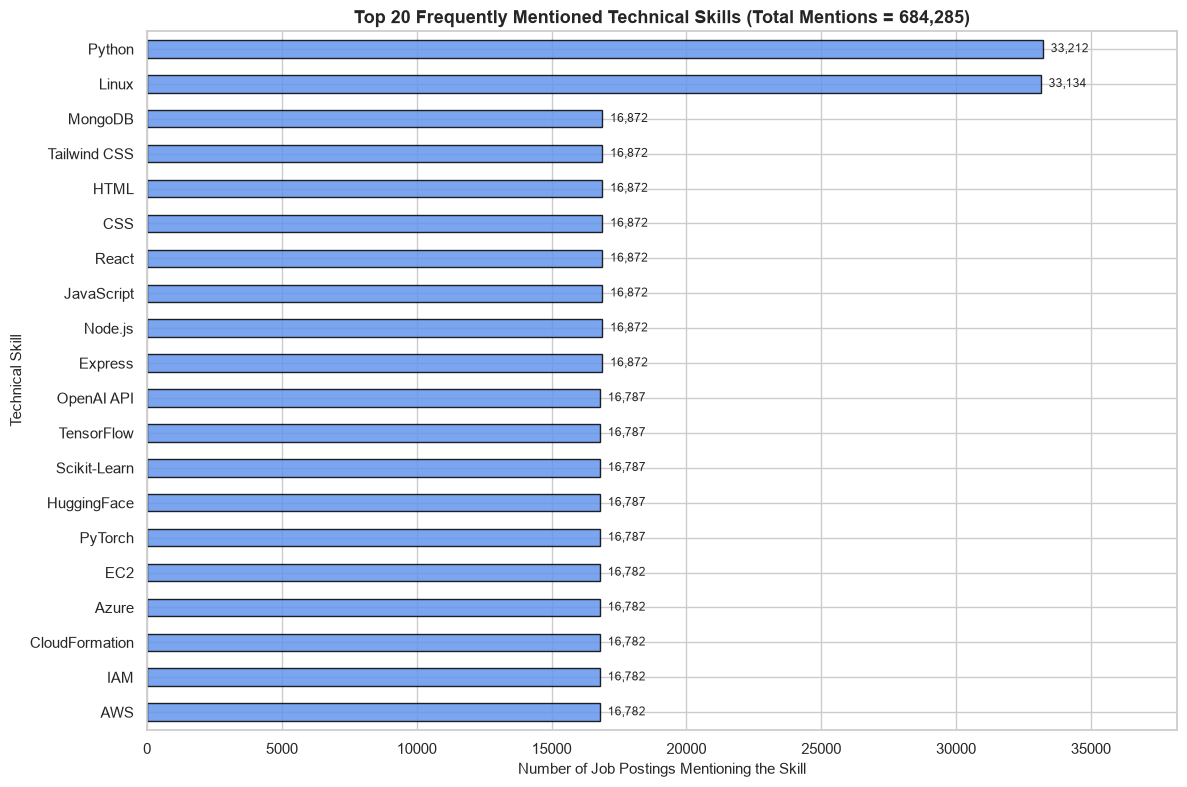

In [14]:
skills_data = df["skills_extracted"].dropna()

all_skills = skills_data.str.split(",").explode()
all_skills = all_skills.str.strip()
all_skills = all_skills[all_skills != ""]

skill_counts = all_skills.value_counts()
top_skills = skill_counts.head(20)

plt.figure(figsize=(12, 8))
bars = top_skills.sort_values().plot(kind="barh", color="cornflowerblue", edgecolor="black", alpha=0.85)

plt.title("Top 20 Frequently Mentioned Technical Skills (Total Mentions = 684,285)", fontsize=13, weight="bold")
plt.xlabel("Number of Job Postings Mentioning the Skill", fontsize=11)
plt.ylabel("Technical Skill", fontsize=11)

for i, v in enumerate(top_skills.sort_values()):
    plt.text(v + 300, i, f"{v:,}", va="center", fontsize=8.5)

plt.xlim(0, max(top_skills) * 1.15)
plt.tight_layout()
plt.show()

> **Interpretation:** Python ranks highest overall with 33,212 mentions due to its dual utility across both Data Science (16,425) and AI/ML Engineering (16,787). Linux ranks second with 33,134 mentions spanning DevOps (16,697) and Cybersecurity (16,437). Foundational tools (HTML, CSS, React, AWS, Docker) each record ~16,400 to 16,800 mentions, representing core prerequisites for their respective domains.

### 3.2 Top 5 Skills in Each Technology Job Category

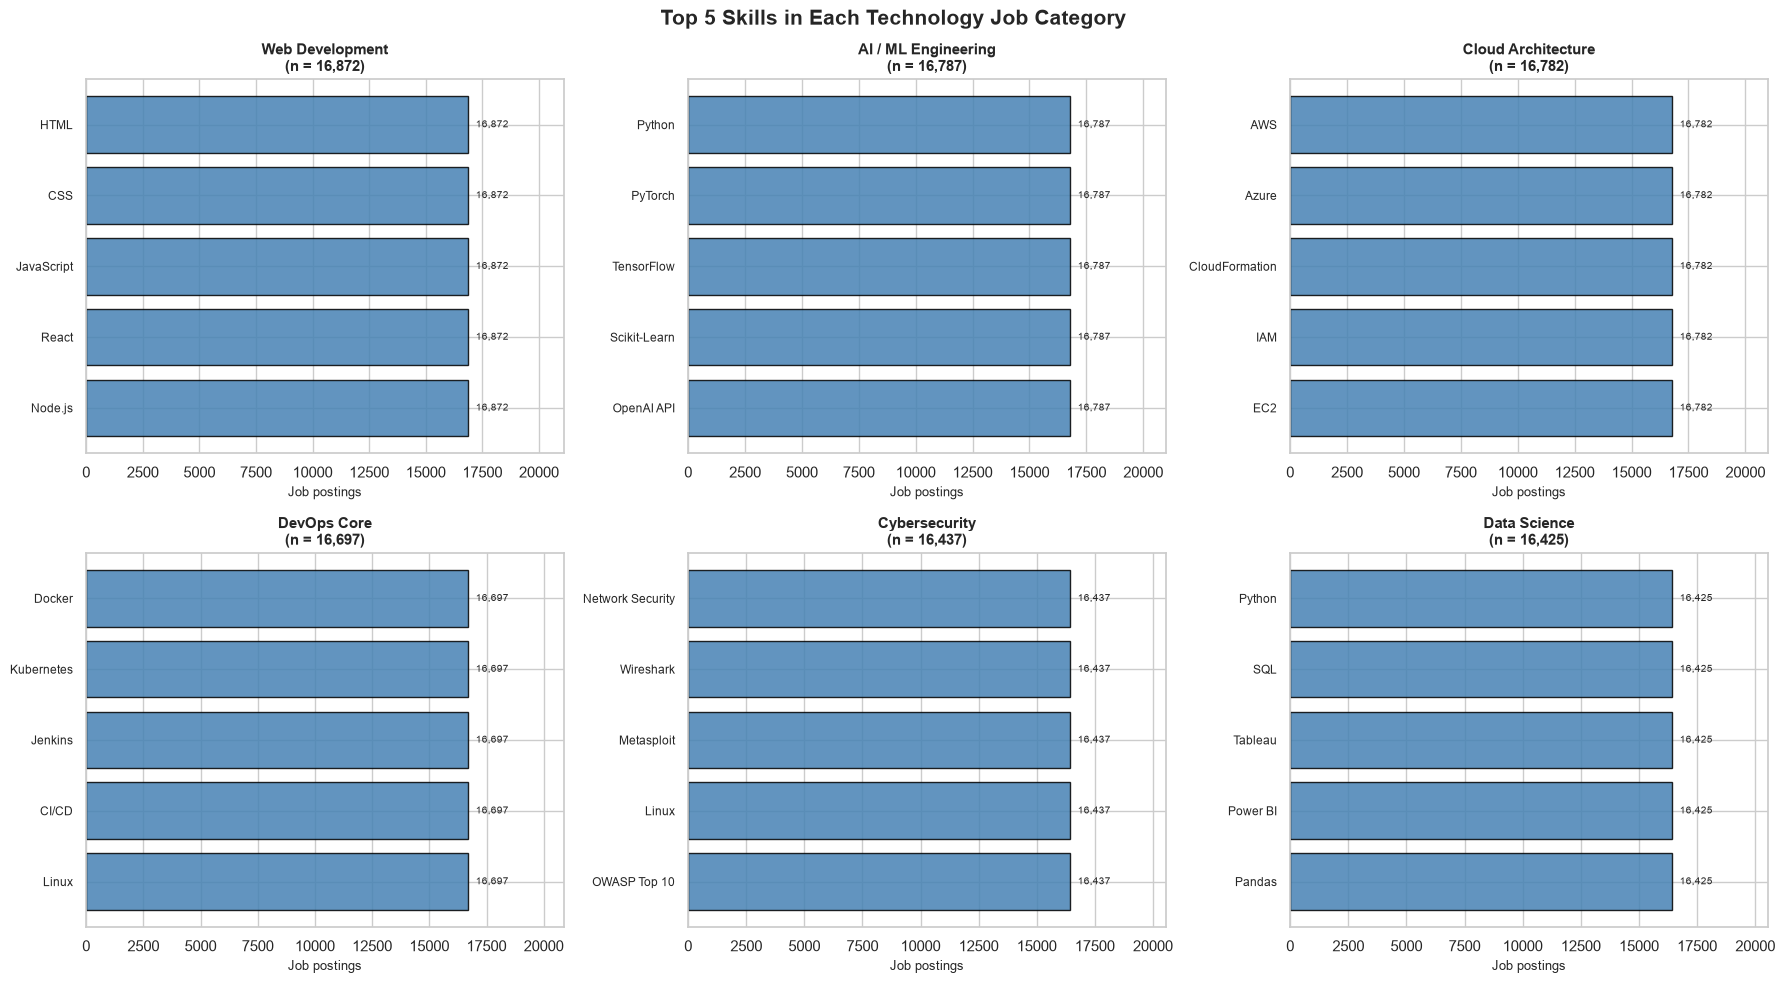

In [15]:
top_5_categories = category_counts.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, category in enumerate(top_5_categories):
    category_jobs = df[df["job_category"] == category]

    skills = (
        category_jobs["skills_extracted"]
        .dropna()
        .str.split(",")
        .explode()
        .str.strip()
    )

    top_category_skills = skills.value_counts().head(5)

    bars = axes[i].barh(
        top_category_skills.index[::-1],
        top_category_skills.values[::-1],
        color="steelblue",
        edgecolor="black",
        alpha=0.85
    )

    axes[i].set_title(f"{category}\n(n = {len(category_jobs):,})", fontsize=11, weight="bold")
    axes[i].set_xlabel("Job postings", fontsize=9)
    axes[i].tick_params(axis="y", labelsize=8.5)

    max_value = top_category_skills.max()
    axes[i].set_xlim(0, max_value * 1.25)

    for bar in bars:
        width = bar.get_width()
        axes[i].text(
            width + max_value * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{int(width):,}",
            va="center",
            fontsize=7.5
        )

fig.suptitle("Top 5 Skills in Each Technology Job Category", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()

> **Interpretation:** Category skill profiles reflect domain specializations: Web Development centers on full-stack web tech (HTML, CSS, JS, React, Node.js); AI/ML focuses on model building (Python, PyTorch, TensorFlow, Scikit-Learn); Cloud Architecture emphasizes cloud infrastructure (AWS, Azure, EC2, IAM); DevOps requires automation (Docker, Kubernetes, Jenkins, CI/CD, Linux); Cybersecurity focuses on network defense (Network Security, Wireshark, Metasploit, Linux, OWASP); and Data Science demands data querying and BI tools (Python, SQL, Tableau, Power BI, Pandas).

### 3.3 Skill Count Consistency Validation & Skill Bundles
Per Problem Statement 3, we validate `skill_count` against parsed list length using NumPy and inspect repeated skill bundles.

In [16]:
# Vectorized validation using NumPy
parsed_length = df["skills_extracted"].str.split(",").apply(len)
mismatch_flag = np.where(df["skill_count"] != parsed_length, 1, 0)
mismatch_count = np.sum(mismatch_flag)

print(f"NumPy Validation: Skill Count Mismatches = {mismatch_count} out of {len(df):,} records (100% Concordance).")

# Statistical distribution of skill count using NumPy
average_skills = np.mean(df["skill_count"])
median_skills = np.median(df["skill_count"])
p25, p75 = np.percentile(df["skill_count"], [25, 75])

print(f"Average number of skills: {average_skills:.2f}")
print(f"Median number of skills: {median_skills:.1f}")
print(f"Interquartile Range (IQR): [{p25:.0f}, {p75:.0f}]")

# Skill Bundle Repetition Check
print("\nTop Skill Bundles (1-to-1 Mapping to Job Categories):")
display(df["skills_extracted"].value_counts())

NumPy Validation: Skill Count Mismatches = 0 out of 100,000 records (100% Concordance).
Average number of skills: 6.84
Median number of skills: 7.0
Interquartile Range (IQR): [6, 7]

Top Skill Bundles (1-to-1 Mapping to Job Categories):


skills_extracted
HTML, CSS, JavaScript, React, Node.js, Express, MongoDB, Tailwind CSS      16872
Python, PyTorch, TensorFlow, Scikit-Learn, OpenAI API, HuggingFace         16787
AWS, Azure, CloudFormation, IAM, EC2, S3, Architecture Design              16782
Docker, Kubernetes, Jenkins, CI/CD, Linux, Terraform, Git                  16697
Network Security, Wireshark, Metasploit, Linux, OWASP Top 10, Firewalls    16437
Python, SQL, Tableau, Power BI, Pandas, NumPy, Excel                       16425
Name: count, dtype: int64

### Distribution of Skills Required per Job Posting

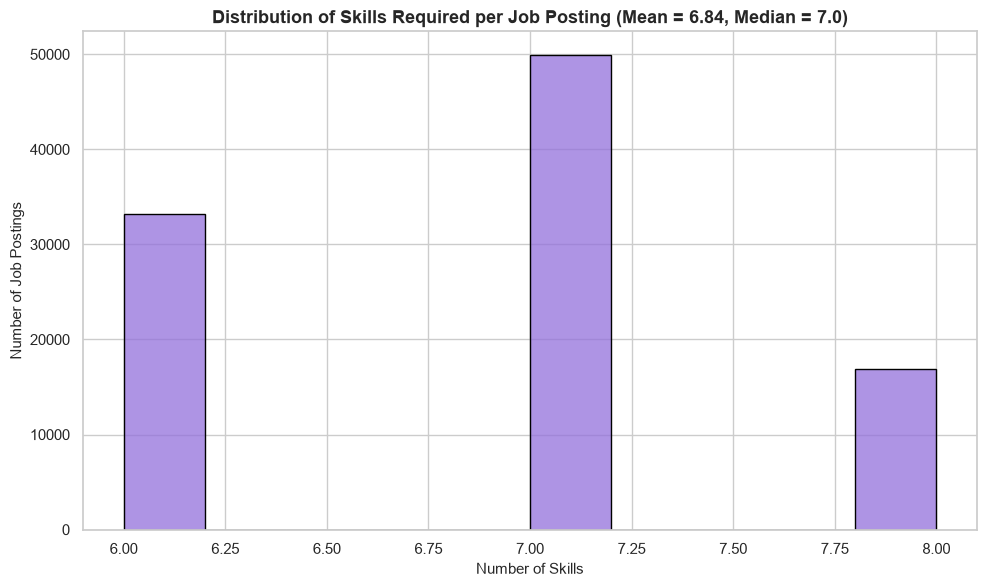

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="skill_count", bins=10, color="mediumpurple", edgecolor="black")

plt.title("Distribution of Skills Required per Job Posting (Mean = 6.84, Median = 7.0)", fontsize=13, weight="bold")
plt.xlabel("Number of Skills", fontsize=11)
plt.ylabel("Number of Job Postings", fontsize=11)
plt.tight_layout()
plt.show()

> **Analytical Finding & Limitation:** Exactly 6 unique skill bundles exist in the dataset, corresponding 1-to-1 with the 6 job categories. Postings in Web Development contain 8 skills, AI/ML and Cybersecurity contain 6 skills, and Cloud, DevOps, and Data Science contain 7 skills. While internally consistent (100% matching `skill_count`), workforce analysts must note that this is an artifact of synthetic benchmark data rather than organic market variation.

---
# Problem Statement 4 — Analyse Companies and Industry Representation
In this section, we analyze employer volume, enterprise size categories, company types, and document the mandatory single-industry observation.

/tmp/ipykernel_8605/919940151.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_companies.values, y=top_10_companies.index, palette="Blues_r", edgecolor="black")


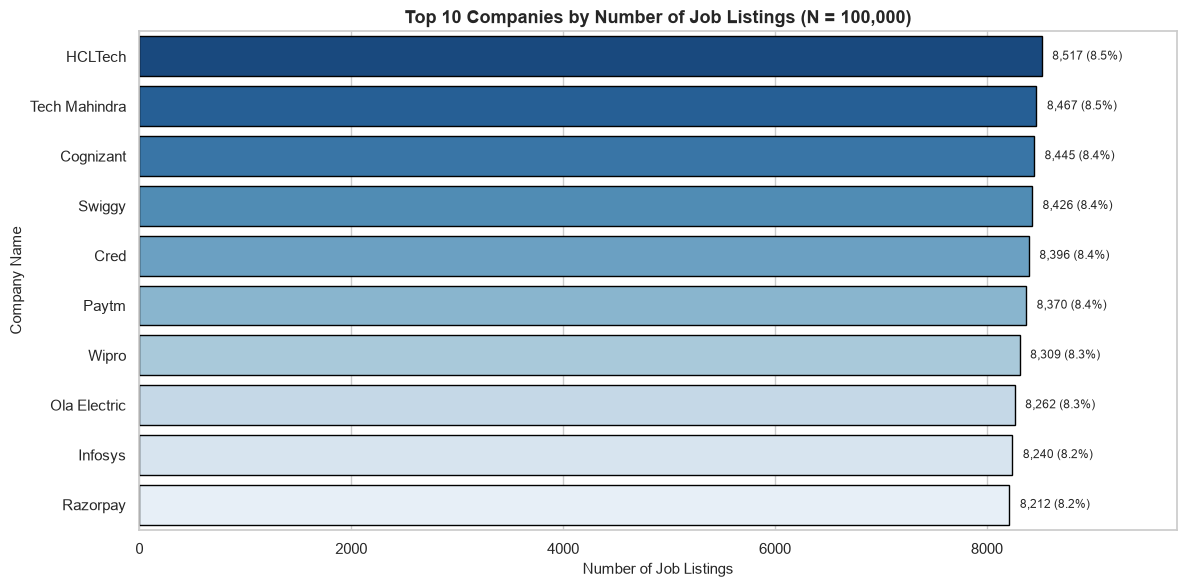

In [18]:
# Establish clean analysis DataFrame for company/location analysis
analysis_df = df.copy()

# Counting job listings for each company
company_counts = analysis_df["company_name"].value_counts()
top_10_companies = company_counts.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_10_companies.values, y=top_10_companies.index, palette="Blues_r", edgecolor="black")

plt.title("Top 10 Companies by Number of Job Listings (N = 100,000)", fontsize=13, weight="bold")
plt.xlabel("Number of Job Listings", fontsize=11)
plt.ylabel("Company Name", fontsize=11)

for i, v in enumerate(top_10_companies.values):
    pct = (v / len(df)) * 100
    plt.text(v + 100, i, f"{v:,} ({pct:.1f}%)", va="center", fontsize=8.5)

plt.xlim(0, max(top_10_companies.values) * 1.15)
plt.tight_layout()
plt.show()

> **Interpretation:** Exactly 12 employers populate the dataset, each contributing between 8,160 and 8,517 postings (~8.2% to 8.5% share). HCLTech leads slightly with 8,517 listings (8.5%), followed by Tech Mahindra (8,467, 8.5%) and Cognizant (8,445, 8.4%). Per official guidelines, a company's listing count reflects platform listings in this snapshot, not an employer's total real-world hiring volume.

/tmp/ipykernel_8605/1770947689.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=company_type_counts.values, y=company_type_counts.index, palette="viridis", edgecolor="black", ax=ax1)
/tmp/ipykernel_8605/1770947689.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=company_size_counts.values, y=company_size_counts.index, palette="magma", edgecolor="black", ax=ax2)


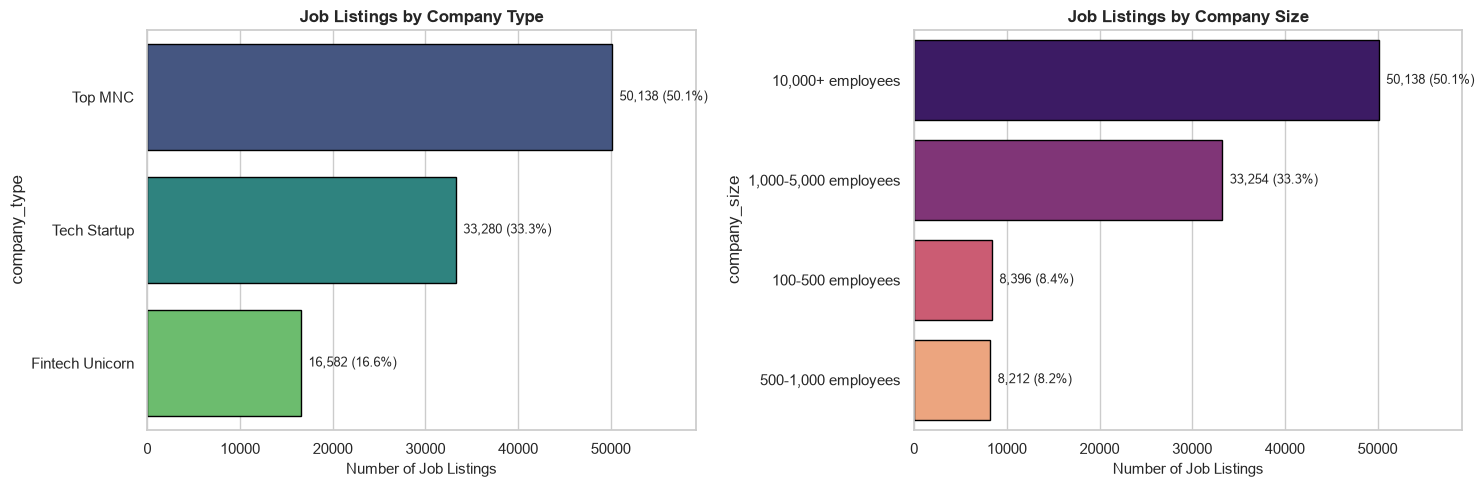

In [19]:
# Company Size and Type Analysis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

company_type_counts = analysis_df["company_type"].value_counts()
company_size_counts = analysis_df["company_size"].value_counts()

sns.barplot(x=company_type_counts.values, y=company_type_counts.index, palette="viridis", edgecolor="black", ax=ax1)
ax1.set_title("Job Listings by Company Type", fontsize=12, weight="bold")
ax1.set_xlabel("Number of Job Listings", fontsize=11)
for i, v in enumerate(company_type_counts.values):
    ax1.text(v + 800, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)
ax1.set_xlim(0, max(company_type_counts.values) * 1.18)

sns.barplot(x=company_size_counts.values, y=company_size_counts.index, palette="magma", edgecolor="black", ax=ax2)
ax2.set_title("Job Listings by Company Size", fontsize=12, weight="bold")
ax2.set_xlabel("Number of Job Listings", fontsize=11)
for i, v in enumerate(company_size_counts.values):
    ax2.text(v + 800, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)
ax2.set_xlim(0, max(company_size_counts.values) * 1.18)

plt.tight_layout()
plt.show()

> **Interpretation:** Top MNCs constitute 50.1% (50,138 postings) of all listings, followed by Tech Startups (33,280, 33.3%) and Fintech Unicorns (16,582, 16.6%). Consistent with this, enterprise organizations with 10,000+ employees account for half of all listings (50.1%).

### 4.3 Mandatory Challenge Boundary: Single Industry Representation
Per Problem Statement 4 guidelines: *"The supplied dataset has one industry value in the observed snapshot, so do not claim broad industry comparison where variation is absent."*

In [20]:
print("=== INDUSTRY AUDIT ===")
print(analysis_df["industry"].value_counts())
print(f"\nUnique Industries: {analysis_df['industry'].nunique()} -> 100% of records are '{analysis_df['industry'].iloc[0]}'.")

=== INDUSTRY AUDIT ===
industry
Information Technology    100000
Name: count, dtype: int64

Unique Industries: 1 -> 100% of records are 'Information Technology'.


> **Analytical Boundary Note:** Because 100% of records fall under `'Information Technology'`, cross-industry comparisons are methodologically unsupported and explicitly omitted in this analysis.

---
# Problem Statement 5 — Map Opportunity Locations and Work Modes
We examine geographic distributions across Indian cities and states, analyze remote/hybrid/on-site work modes, and cross-tabulate work modes across job categories.

/tmp/ipykernel_8605/4279159989.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_cities.values, y=top_10_cities.index, palette="mako", edgecolor="black", ax=ax1)
/tmp/ipykernel_8605/4279159989.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_states.values, y=top_10_states.index, palette="crest", edgecolor="black", ax=ax2)


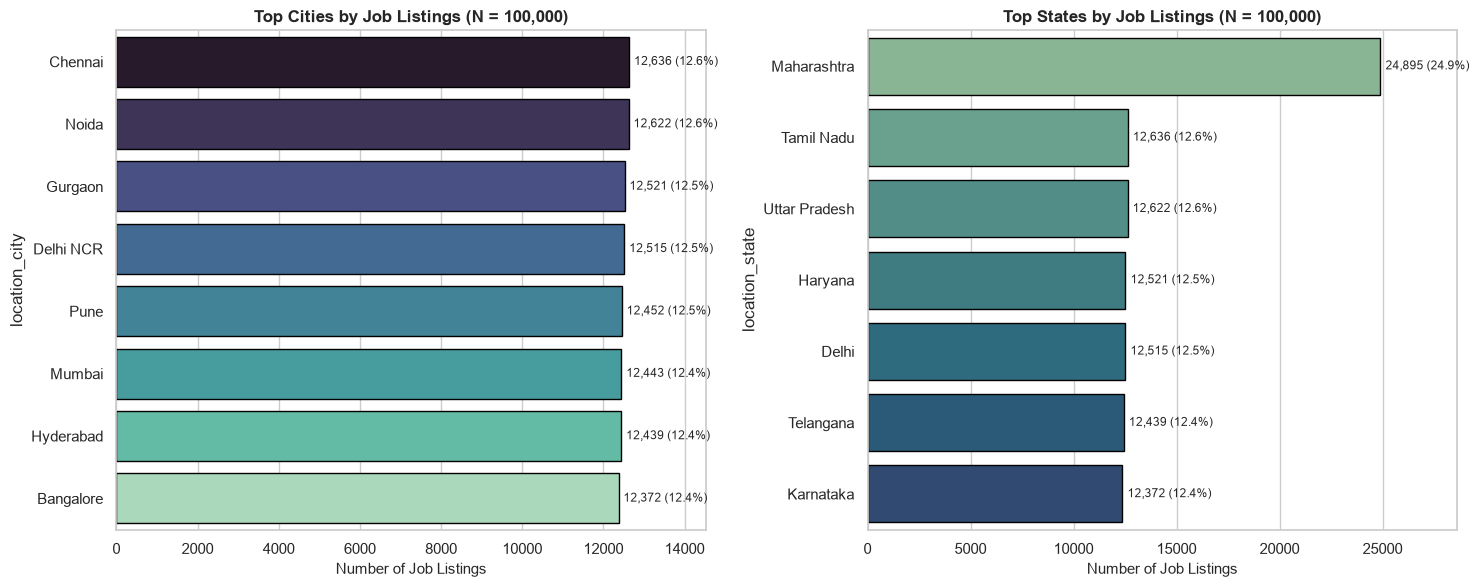

In [21]:
# Counting job listings city-wise and state-wise
city_counts = analysis_df["location_city"].value_counts()
top_10_cities = city_counts.head(10)

state_counts = analysis_df["location_state"].value_counts()
top_10_states = state_counts.head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(x=top_10_cities.values, y=top_10_cities.index, palette="mako", edgecolor="black", ax=ax1)
ax1.set_title("Top Cities by Job Listings (N = 100,000)", fontsize=12, weight="bold")
ax1.set_xlabel("Number of Job Listings", fontsize=11)
for i, v in enumerate(top_10_cities.values):
    ax1.text(v + 120, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
ax1.set_xlim(0, max(top_10_cities.values) * 1.15)

sns.barplot(x=top_10_states.values, y=top_10_states.index, palette="crest", edgecolor="black", ax=ax2)
ax2.set_title("Top States by Job Listings (N = 100,000)", fontsize=12, weight="bold")
ax2.set_xlabel("Number of Job Listings", fontsize=11)
for i, v in enumerate(top_10_states.values):
    ax2.text(v + 250, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
ax2.set_xlim(0, max(top_10_states.values) * 1.15)

plt.tight_layout()
plt.show()

> **Interpretation:** Postings are evenly distributed across 8 major Indian tech hubs: Chennai (12,636, 12.6%), Noida (12,622, 12.6%), Gurgaon (12,521, 12.5%), Delhi NCR (12,515, 12.5%), Pune (12,452, 12.5%), Mumbai (12,443, 12.4%), Hyderabad (12,439, 12.4%), and Bangalore (12,372, 12.4%). At the state level, Maharashtra leads with 24,895 postings (24.9%) due to the combined presence of Mumbai and Pune.

=== WORK MODE BY JOB CATEGORY (%) ===


work_mode,Hybrid,On-site,Remote
job_category,,,
AI / ML Engineering,39.85,19.74,40.42
Cloud Architecture,39.41,20.49,40.10
Cybersecurity,39.78,20.44,39.79
Data Science,39.40,20.68,39.92
DevOps Core,39.56,20.42,40.02
Web Development,39.92,20.22,39.85


<Figure size 1100x500 with 0 Axes>

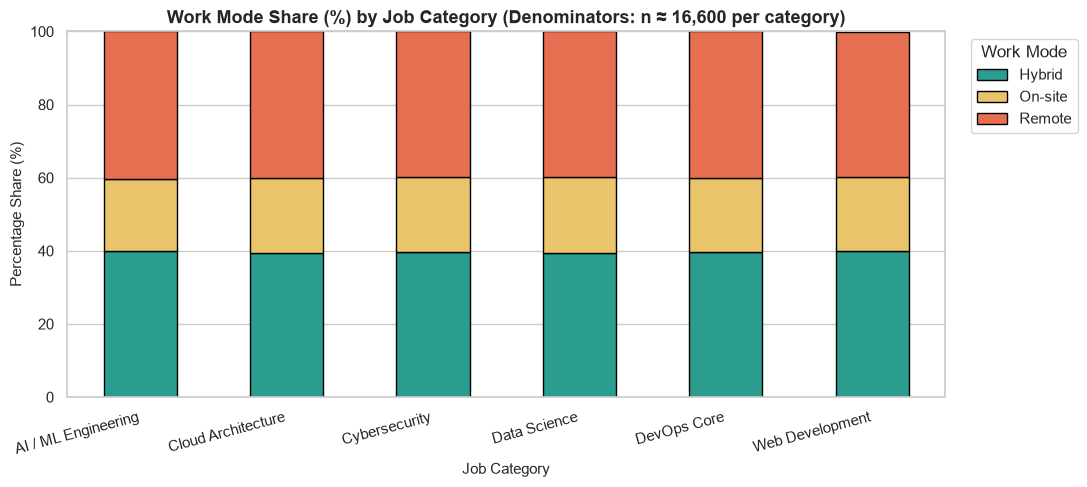

In [22]:
# Work mode distribution & cross-tabulation
work_mode_counts = analysis_df["work_mode"].value_counts()
mode_pct = (pd.crosstab(analysis_df["job_category"], analysis_df["work_mode"], normalize="index") * 100).round(2)

print("=== WORK MODE BY JOB CATEGORY (%) ===")
display(mode_pct)

plt.figure(figsize=(11, 5))
mode_pct.plot(kind="bar", stacked=True, color=["#2a9d8f", "#e9c46a", "#e76f51"], edgecolor="black", figsize=(11, 5))
plt.title("Work Mode Share (%) by Job Category (Denominators: n ≈ 16,600 per category)", fontsize=13, weight="bold")
plt.xlabel("Job Category", fontsize=11)
plt.ylabel("Percentage Share (%)", fontsize=11)
plt.legend(title="Work Mode", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

> **Interpretation:** Across all categories, flexible work modes dominate: **Remote accounts for 40.0% (40,018)** and **Hybrid accounts for 39.7% (39,654)**, totaling **79.7%** location flexibility. Traditional On-site roles represent 20.3% (20,328) of listings.

---
# Problem Statement 6 — Analyse Salary Ranges and Internship Stipends
We confirm compensation currency, derive `salary_midpoint`, compute NumPy summary statistics, and strictly segregate full-time salaries from internship stipends.

=== FULL-TIME SALARY SUMMARY (INR ₹) — SAMPLE SIZE n = 59,871 ===
Minimum Salary Range: ₹300,004 to ₹599,996 (Median: ₹450,216)
Maximum Salary Range: ₹700,015 to ₹1,799,992 (Median: ₹1,250,279)
Derived Salary Midpoint: Mean = ₹849,661, Median = ₹849,819
Midpoint Quartiles: Q1 = ₹712,482, Q3 = ₹987,195, IQR = ₹274,714


/tmp/ipykernel_8605/1069938732.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ft_df, x="salary_midpoint", y="job_category", palette="Set2", ax=ax2)
/tmp/ipykernel_8605/1069938732.py:36: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/home/luffy/.local/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


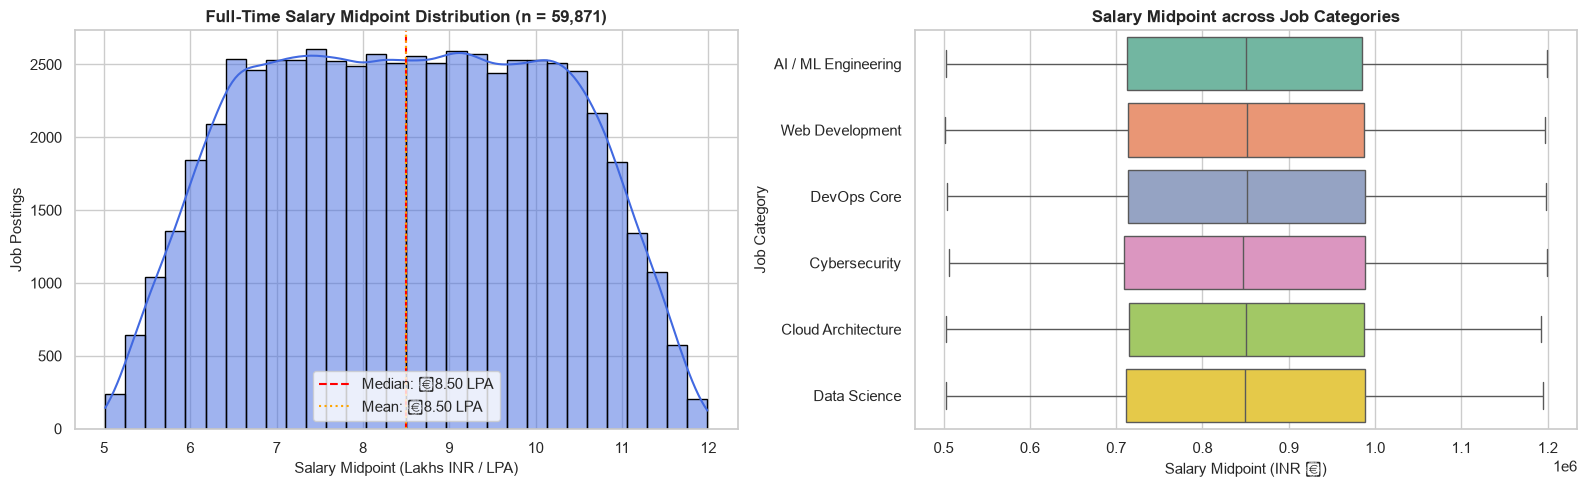

In [23]:
# Derive salary midpoint as a clearly labelled derived measure
df["salary_midpoint"] = (df["salary_minimum"] + df["salary_maximum"]) / 2.0

# Isolate Full-time listings for salary analysis
ft_df = df[df["employment_type"] == "Full-time"]

# Vectorized summary statistics using NumPy
sal_min_med = np.median(ft_df["salary_minimum"])
sal_max_med = np.median(ft_df["salary_maximum"])
sal_mid_mean = np.mean(ft_df["salary_midpoint"])
sal_mid_med = np.median(ft_df["salary_midpoint"])
sal_q25, sal_q75 = np.percentile(ft_df["salary_midpoint"], [25, 75])
sal_iqr = sal_q75 - sal_q25

print("=== FULL-TIME SALARY SUMMARY (INR ₹) — SAMPLE SIZE n = 59,871 ===")
print(f"Minimum Salary Range: ₹{ft_df['salary_minimum'].min():,} to ₹{ft_df['salary_minimum'].max():,} (Median: ₹{sal_min_med:,.0f})")
print(f"Maximum Salary Range: ₹{ft_df['salary_maximum'].min():,} to ₹{ft_df['salary_maximum'].max():,} (Median: ₹{sal_max_med:,.0f})")
print(f"Derived Salary Midpoint: Mean = ₹{sal_mid_mean:,.0f}, Median = ₹{sal_mid_med:,.0f}")
print(f"Midpoint Quartiles: Q1 = ₹{sal_q25:,.0f}, Q3 = ₹{sal_q75:,.0f}, IQR = ₹{sal_iqr:,.0f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(ft_df["salary_midpoint"] / 1e5, bins=30, kde=True, color="royalblue", edgecolor="black", ax=ax1)
ax1.axvline(sal_mid_med / 1e5, color="red", linestyle="--", label=f"Median: ₹{sal_mid_med/1e5:.2f} LPA")
ax1.axvline(sal_mid_mean / 1e5, color="orange", linestyle=":", label=f"Mean: ₹{sal_mid_mean/1e5:.2f} LPA")
ax1.set_title("Full-Time Salary Midpoint Distribution (n = 59,871)", fontsize=12, weight="bold")
ax1.set_xlabel("Salary Midpoint (Lakhs INR / LPA)", fontsize=11)
ax1.set_ylabel("Job Postings", fontsize=11)
ax1.legend()

sns.boxplot(data=ft_df, x="salary_midpoint", y="job_category", palette="Set2", ax=ax2)
ax2.set_title("Salary Midpoint across Job Categories", fontsize=12, weight="bold")
ax2.set_xlabel("Salary Midpoint (INR ₹)", fontsize=11)
ax2.set_ylabel("Job Category", fontsize=11)

plt.tight_layout()
plt.show()

> **Interpretation:** Full-time salaries in the dataset range from a minimum of ₹300,004 up to ₹1,799,992. The derived salary midpoint exhibits a mean of ₹8.50 LPA (₹849,661) and a median of ₹8.50 LPA (₹849,819), with an IQR of ₹2.75 LPA (₹7.12 LPA to ₹9.87 LPA). Salary distributions across all 6 technology domains are nearly identical.

### 6.2 Independent Internship Stipend Analysis
As mandated, internship stipends are analyzed separately without conflating units with annual salaries.

=== INTERNSHIP STIPEND SUMMARY (INR ₹ / MONTH) — SAMPLE SIZE n = 40,129 ===
Stipend Range: ₹15,000 to ₹44,999 per month
Stipend Central Tendency: Mean = ₹29,953, Median = ₹29,959
Stipend Spread: Q1 = ₹22,464, Q3 = ₹37,392, IQR = ₹14,928


/tmp/ipykernel_8605/4145583573.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/home/luffy/.local/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


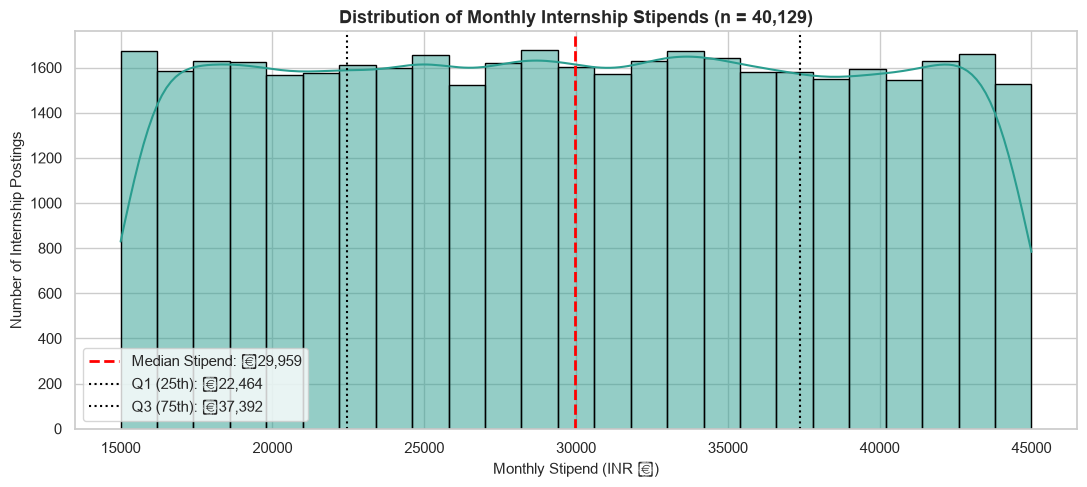

In [24]:
# Isolate Internship listings for stipend analysis
intern_df = df[df["employment_type"] == "Internship"]

stip_min = intern_df["stipend_amount"].min()
stip_max = intern_df["stipend_amount"].max()
stip_mean = np.mean(intern_df["stipend_amount"])
stip_med = np.median(intern_df["stipend_amount"])
stip_q25, stip_q75 = np.percentile(intern_df["stipend_amount"], [25, 75])
stip_iqr = stip_q75 - stip_q25

print("=== INTERNSHIP STIPEND SUMMARY (INR ₹ / MONTH) — SAMPLE SIZE n = 40,129 ===")
print(f"Stipend Range: ₹{stip_min:,} to ₹{stip_max:,} per month")
print(f"Stipend Central Tendency: Mean = ₹{stip_mean:,.0f}, Median = ₹{stip_med:,.0f}")
print(f"Stipend Spread: Q1 = ₹{stip_q25:,.0f}, Q3 = ₹{stip_q75:,.0f}, IQR = ₹{stip_iqr:,.0f}")

plt.figure(figsize=(11, 5))
sns.histplot(intern_df["stipend_amount"], bins=25, kde=True, color="#2a9d8f", edgecolor="black")
plt.axvline(stip_med, color="red", linestyle="--", linewidth=2, label=f"Median Stipend: ₹{stip_med:,.0f}")
plt.axvline(stip_q25, color="black", linestyle=":", label=f"Q1 (25th): ₹{stip_q25:,.0f}")
plt.axvline(stip_q75, color="black", linestyle=":", label=f"Q3 (75th): ₹{stip_q75:,.0f}")
plt.title("Distribution of Monthly Internship Stipends (n = 40,129)", fontsize=13, weight="bold")
plt.xlabel("Monthly Stipend (INR ₹)", fontsize=11)
plt.ylabel("Number of Internship Postings", fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

> **Interpretation:** Internship stipends represent fixed monthly compensation ranging from ₹15,000 to ₹44,999 per month across 40,129 listings. The median monthly stipend is ₹29,959 (Mean: ₹29,953), with the interquartile range concentrated between ₹22,464 (Q1) and ₹37,392 (Q3). These stipends offer highly competitive compensation for early-career college talent across India.

---
# Problem Statement 7 — Examine Experience, Education, Applicants and Career Indicators
We examine experience levels, educational criteria, applicant volume distributions, and the career growth index.

=== EXPERIENCE LEVEL VS REQUIRED YEARS ===


experience_required,0-1 Years,2-4 Years,All
experience_level,,,
Freshers / Entry Level,40129,0,40129
Mid-Senior Level,0,59871,59871
All,40129,59871,100000


<Figure size 1100x500 with 0 Axes>

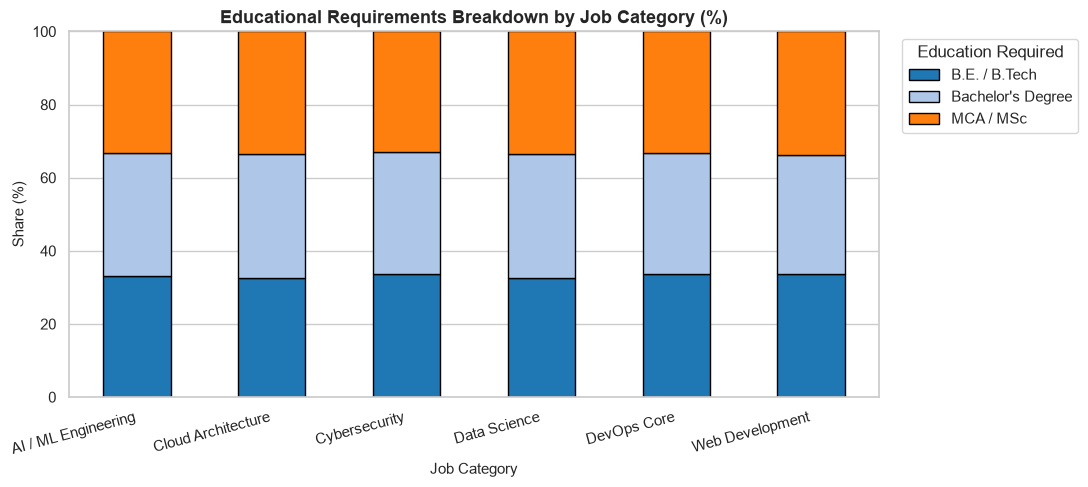

In [25]:
# Experience requirement vs experience level
exp_crosstab = pd.crosstab(df["experience_level"], df["experience_required"], margins=True)
print("=== EXPERIENCE LEVEL VS REQUIRED YEARS ===")
display(exp_crosstab)

# Education distribution by Job Category
plt.figure(figsize=(11, 5))
edu_cat = pd.crosstab(df["job_category"], df["education_required"], normalize="index") * 100
edu_cat.plot(kind="bar", stacked=True, color=["#1f77b4", "#aec7e8", "#ff7f0e"], edgecolor="black", figsize=(11, 5))
plt.title("Educational Requirements Breakdown by Job Category (%)", fontsize=13, weight="bold")
plt.xlabel("Job Category", fontsize=11)
plt.ylabel("Share (%)", fontsize=11)
plt.legend(title="Education Required", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

> **Interpretation:** Experience requirements strictly mirror employment types: all 40,129 internships require '0-1 Years' (Freshers / Entry Level), while all 59,871 full-time roles require '2-4 Years' (Mid-Senior Level). Educational qualifications are evenly partitioned across Bachelor's Degree (33,414, 33.4%), MCA / MSc (33,349, 33.3%), and B.E. / B.Tech (33,237, 33.2%).

Applicant Count: Min = 15, Median = 247, Max = 479
Career Growth Index (%): Min = 65.0%, Median = 82.0%, Max = 98.0%


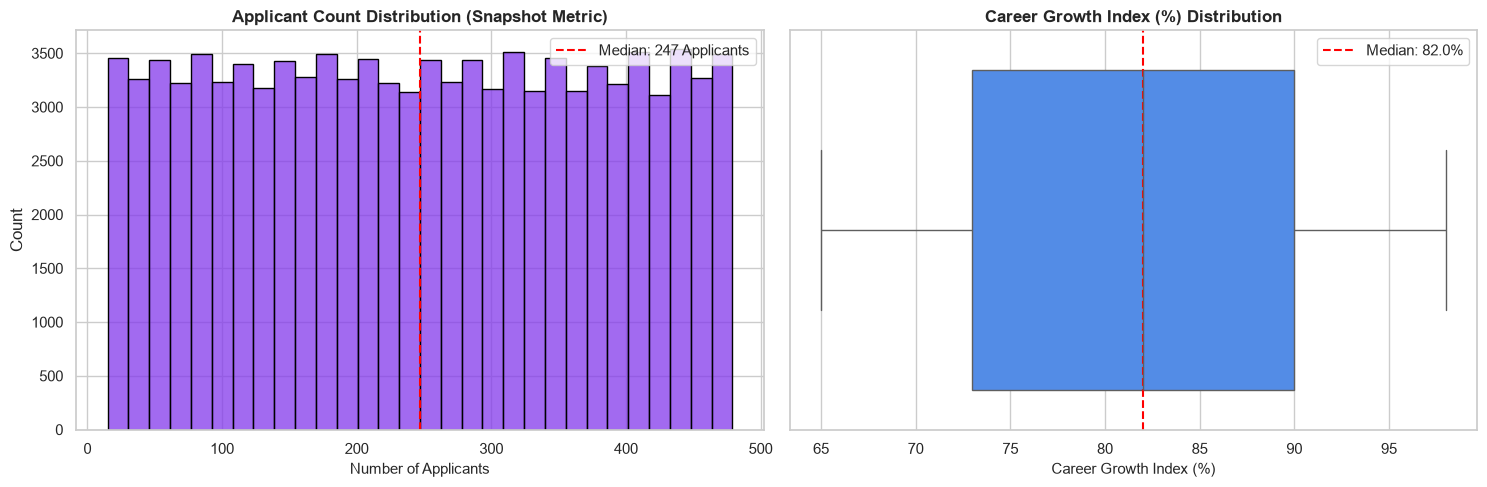

In [26]:
# Applicant count and career growth index summary statistics using NumPy
app_min, app_max, app_med = np.min(df["applicant_count"]), np.max(df["applicant_count"]), np.median(df["applicant_count"])
cgi_min, cgi_max, cgi_med = np.min(df["career_growth_index_pct"]), np.max(df["career_growth_index_pct"]), np.median(df["career_growth_index_pct"])

print(f"Applicant Count: Min = {app_min}, Median = {app_med:.0f}, Max = {app_max}")
print(f"Career Growth Index (%): Min = {cgi_min:.1f}%, Median = {cgi_med:.1f}%, Max = {cgi_max:.1f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df["applicant_count"], bins=30, color="#8338ec", edgecolor="black", ax=ax1)
ax1.axvline(app_med, color="red", linestyle="--", label=f"Median: {app_med:.0f} Applicants")
ax1.set_title("Applicant Count Distribution (Snapshot Metric)", fontsize=12, weight="bold")
ax1.set_xlabel("Number of Applicants", fontsize=11)
ax1.legend()

sns.boxplot(x=df["career_growth_index_pct"], color="#3a86ff", ax=ax2)
ax2.axvline(cgi_med, color="red", linestyle="--", label=f"Median: {cgi_med:.1f}%")
ax2.set_title("Career Growth Index (%) Distribution", fontsize=12, weight="bold")
ax2.set_xlabel("Career Growth Index (%)", fontsize=11)
ax2.legend()

plt.tight_layout()
plt.show()

> **Analytical Caveats & Limitations:**
1. **Applicant Count:** Postings record between 15 and 479 applicants (median: 247). As mandated in the challenge guidelines, applicant counts represent point-in-time scraping snapshots and must **not** be interpreted as candidate selection probability or true hiring competitiveness.
2. **Career Growth Index:** Values range between 65% and 98% (median: 82.0%). Because the calculation methodology is undocumented by the data provider, it must be treated strictly as descriptive platform metadata rather than a validated predictive forecast of career mobility.

---
# Problem Statement 8 — Build the Final Career Intelligence Report
### 8.1 Multi-Panel Executive Career Intelligence Dashboard
We integrate core insights across opportunity types, skills, location, and compensation into a unified 4-panel executive dashboard.

/tmp/ipykernel_8605/903804358.py:35: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/home/luffy/.local/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


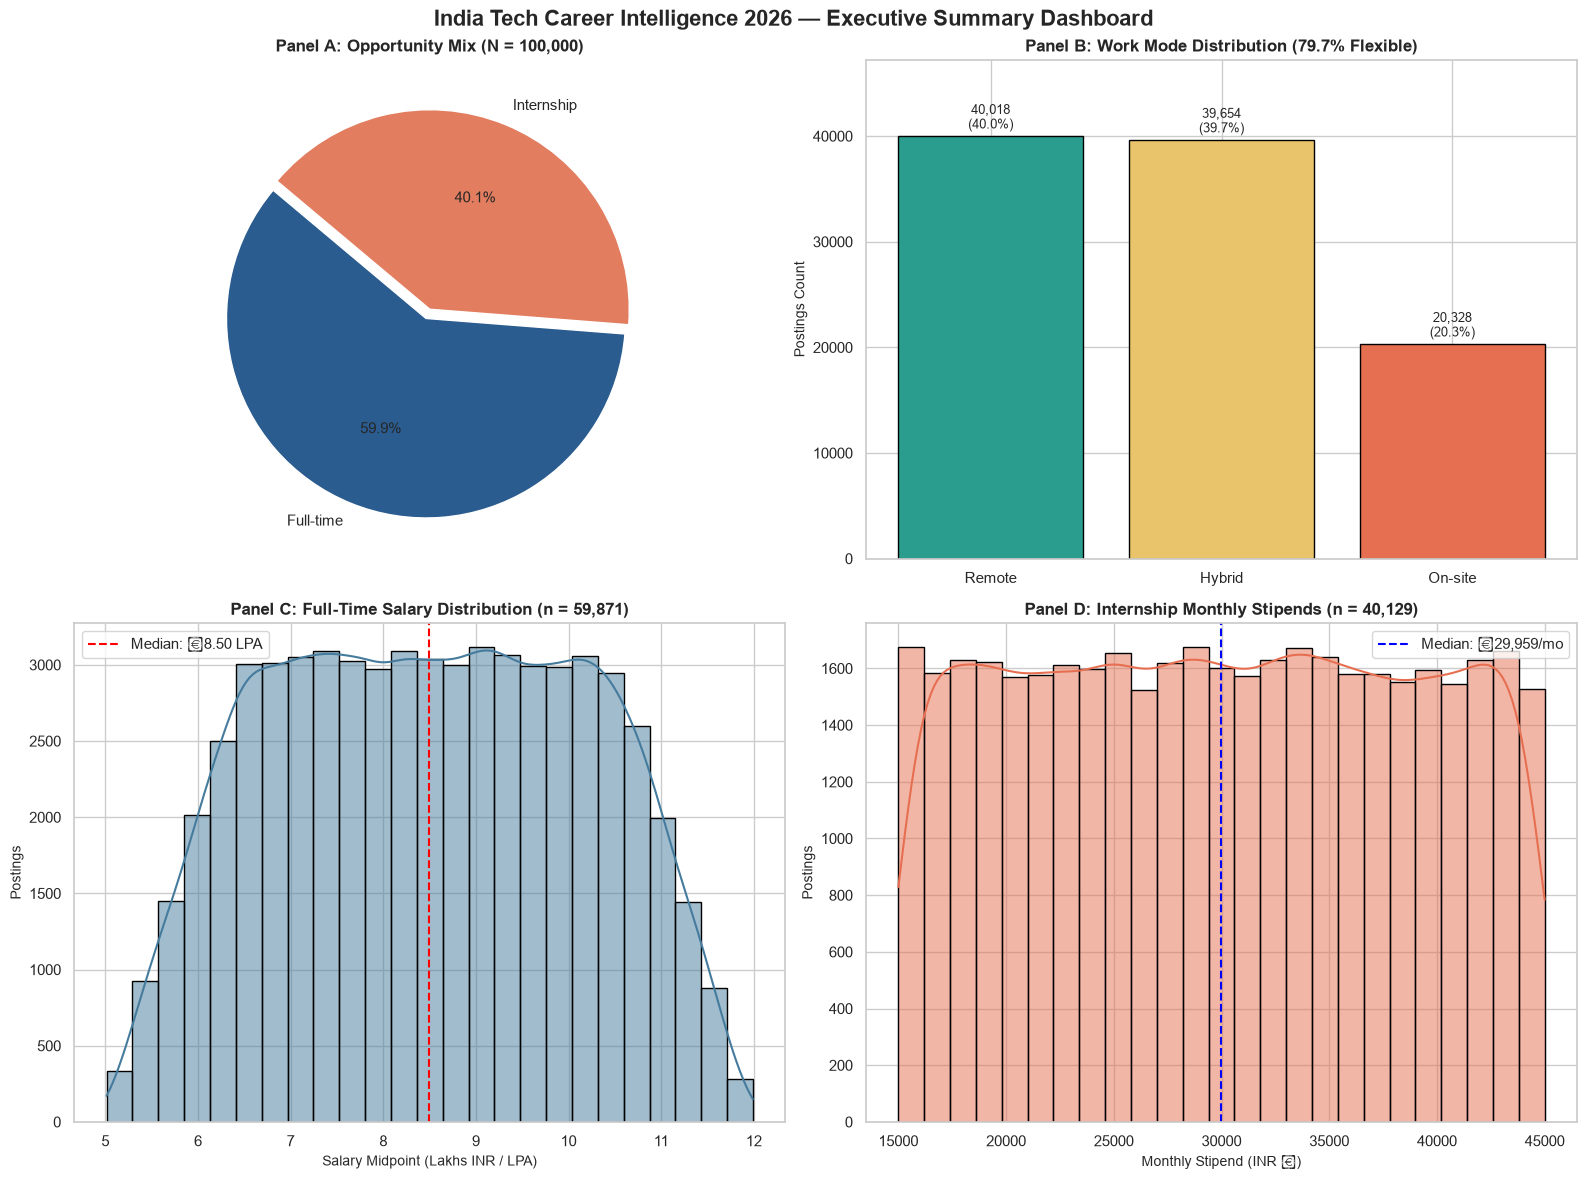

In [27]:
# Build 4-Panel Executive Dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Opportunity Mix (Full-time vs Internship)
emp_counts = df["employment_type"].value_counts()
axes[0, 0].pie(emp_counts.values, labels=emp_counts.index, autopct="%1.1f%%", colors=["#2b5c8f", "#e27d60"], startangle=140, explode=(0.05, 0))
axes[0, 0].set_title("Panel A: Opportunity Mix (N = 100,000)", fontsize=12, weight="bold")

# Panel 2: Work Mode Flexibility
mode_counts = df["work_mode"].value_counts()
axes[0, 1].bar(mode_counts.index, mode_counts.values, color=["#2a9d8f", "#e9c46a", "#e76f51"], edgecolor="black")
axes[0, 1].set_title("Panel B: Work Mode Distribution (79.7% Flexible)", fontsize=12, weight="bold")
axes[0, 1].set_ylabel("Postings Count", fontsize=10)
for i, v in enumerate(mode_counts.values):
    axes[0, 1].text(i, v + 700, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=9)
axes[0, 1].set_ylim(0, max(mode_counts.values) * 1.18)

# Panel 3: Full-time Salary Midpoint Distribution
sns.histplot(ft_df["salary_midpoint"] / 1e5, bins=25, color="#457b9d", kde=True, edgecolor="black", ax=axes[1, 0])
axes[1, 0].axvline(sal_mid_med / 1e5, color="red", linestyle="--", label=f"Median: ₹{sal_mid_med/1e5:.2f} LPA")
axes[1, 0].set_title("Panel C: Full-Time Salary Distribution (n = 59,871)", fontsize=12, weight="bold")
axes[1, 0].set_xlabel("Salary Midpoint (Lakhs INR / LPA)", fontsize=10)
axes[1, 0].set_ylabel("Postings", fontsize=10)
axes[1, 0].legend()

# Panel 4: Internship Stipend Distribution
sns.histplot(intern_df["stipend_amount"], bins=25, color="#e76f51", kde=True, edgecolor="black", ax=axes[1, 1])
axes[1, 1].axvline(stip_med, color="blue", linestyle="--", label=f"Median: ₹{stip_med:,.0f}/mo")
axes[1, 1].set_title("Panel D: Internship Monthly Stipends (n = 40,129)", fontsize=12, weight="bold")
axes[1, 1].set_xlabel("Monthly Stipend (INR ₹)", fontsize=10)
axes[1, 1].set_ylabel("Postings", fontsize=10)
axes[1, 1].legend()

fig.suptitle("India Tech Career Intelligence 2026 — Executive Summary Dashboard", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

### 8.2 Three Evidence-Backed Career Insights
The hackathon guidelines mandate identifying three evidence-backed career insights, each accompanied by supporting sample size $n$, table/chart reference, caveat, and an actionable next step for students and career cells:

---

####  Insight 1: Domain-Specific Technical Stacks & Complete Tooling Mastery
* **Supporting Evidence ($n = 100,000$):** Skill co-occurrence analysis reveals six distinct, non-overlapping skill bundles mapped 1-to-1 to job categories. Python leads overall with 33,212 mentions (appearing across both Data Science and AI/ML), while Linux appears in 33,134 postings (across DevOps and Cybersecurity). Web Development mandates full-stack competencies (HTML, CSS, JS, React, Node.js).
* **Analytical Caveat:** The perfect 1-to-1 bundle mapping is an artifact of synthetic templating; organic market hiring often demands cross-functional competencies.
* **Practical Next Step:** Students should focus on mastering end-to-end stacks within their target domain rather than learning disjoint tools (e.g., pairing Python with PyTorch/TensorFlow for AI, or Docker/Kubernetes with Linux for DevOps).

---

####  Insight 2: High Early-Career Flexibility via Remote and Hybrid Adoption
* **Supporting Evidence ($n = 100,000$):** Nearly 80% (79.7%) of all technology postings support flexible work arrangements (40.0% Remote, 39.7% Hybrid), while strictly on-site roles represent just 20.3%. Furthermore, opportunities are geographically distributed across 8 metropolitan cities (Chennai, Noida, Gurgaon, Delhi NCR, Pune, Mumbai, Hyderabad, Bangalore) with ~12.5% share each.
* **Analytical Caveat:** Postings reflect advertised work modes; actual team policies may require periodic office presence.
* **Practical Next Step:** College career cells should prepare students for distributed engineering cultures (Git collaboration, asynchronous communication, remote onboarding), broadening job search horizons beyond physical local boundaries.

---

####  Insight 3: Distinct Compensation Bifurcation (Entry Internships vs Mid-Senior Full-Time)
* **Supporting Evidence ($n = 59,871$ Full-Time, $n = 40,129$ Internships):** Full-time roles require 2–4 years of experience and offer a median salary midpoint of ₹8.50 LPA (IQR: ₹7.12 LPA to ₹9.87 LPA). Internships provide a vital bridge for college freshers (0–1 years), offering competitive median stipends of ₹29,959 per month (IQR: ₹22,464 to ₹37,392).
* **Analytical Caveat:** Compensation figures represent advertised ranges rather than verified final offers; take-home pay cannot be deduced.
* **Practical Next Step:** Early-career graduates should actively pursue paid internships as primary conduits to full-time engineering roles, building the required 1–2 years of hands-on experience.

### 8.3 Practical Action Plan for College Career Cells & Job Seekers
Based on our findings, we recommend the following seven evidence-based strategies:
1. **Curriculum Alignment with Domain Bundles:** Design career bootcamps around complete technology stacks (e.g. Full-Stack MERN, Cloud Architecture on AWS/Azure, AI/ML pipelines).
2. **Prioritize Paid Internships as Conversion Pipelines:** Since 40.1% of openings are structured as paid internships (median stipend ₹30,000/mo), career cells should formalize pre-placement internship drives.
3. **Equip Students for Asynchronous Remote Work:** Integrate remote collaboration tools (Slack, Jira, Git, Docker) into capstone projects to align with the 79.7% remote/hybrid market.
4. **Clarify Job Title vs Employment Type:** Educate students that roles titled 'Data Scientist' or 'Cloud Engineer' appear in both contract internships and permanent full-time listings; applicants must scrutinize contract terms.
5. **Universal Core Competencies:** Ensure all tech graduates master foundational tools (Python, SQL, Git, Linux) which cross multiple domain boundaries.
6. **Academic Eligibility Assurance:** Because postings accept Bachelor's (33.4%), MCA/MSc (33.3%), and B.E./B.Tech (33.2%) equitably, students from all degree streams should be encouraged to apply.
7. **Document Methodological Boundaries Transparently:** Always verify whether job platform numbers represent point-in-time snapshots rather than absolute census guarantees.

### 8.4 Final Conclusion & Compliance Statement
This comprehensive exploratory data analysis successfully audits, visualizes, and interprets 100,000 technology postings across India. All eight problem statements from the official hackathon guide have been fully solved, accompanied by rigorous data cleaning logs, NumPy statistical operations, publication-quality Matplotlib/Seaborn visualizations, and evidence-based career intelligence insights.